# EDA: UCI Energy Efficiency (вариант 29, две цели)

Датасет 768×10: 8 признаков формы здания и остекления, две целевые величины —
нагрузка на отопление (`Y1`, heating load) и на охлаждение (`Y2`, cooling load).
Задача — регрессия с двумя выходами, поэтому EDA должен показать и структуру
данных, и то, насколько цели согласованы, и как устроено разбиение.

In [23]:
import os

__file__ = os.getcwd()

In [37]:
import json
from pathlib import Path
import hashlib

ROOT = Path(__file__).resolve()
OUT = Path(__file__).resolve() / "data"
DATA_XLSX = ROOT / "data" / "ENB2012_data.xlsx"
DATA_ZIP = ROOT / "data" / "energy_efficiency.zip"
MANIFEST = ROOT / "data" / "MANIFEST.sha256"

ROOT, OUT, DATA_XLSX, DATA_ZIP, MANIFEST

(PosixPath('/home/ufguff/Documents/1 University/energy-intellectiual-systems'),
 PosixPath('/home/ufguff/Documents/1 University/energy-intellectiual-systems/data'),
 PosixPath('/home/ufguff/Documents/1 University/energy-intellectiual-systems/data/ENB2012_data.xlsx'),
 PosixPath('/home/ufguff/Documents/1 University/energy-intellectiual-systems/data/energy_efficiency.zip'),
 PosixPath('/home/ufguff/Documents/1 University/energy-intellectiual-systems/data/MANIFEST.sha256'))

In [38]:
def sha256(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def write_manifest() -> dict:
    expected = {}
    if MANIFEST.exists():
        for line in MANIFEST.read_text(encoding="utf-8").splitlines():
            parts = line.split()
            if len(parts) == 2:
                expected[parts[1]] = parts[0]

    items = []
    for path in (DATA_XLSX, DATA_ZIP):
        rel = path.relative_to(ROOT).as_posix()
        digest = sha256(path)
        items.append(
            {
                "path": rel,
                "sha256": digest,
                "size_bytes": path.stat().st_size,
                "manifest_match": expected.get(path.name) == digest,
            }
        )
    manifest = {
        "algorithm": "sha256",
        "verified_against": "data/MANIFEST.sha256",
        "all_match": all(item["manifest_match"] for item in items),
        "files": items,
    }
    (OUT / "hash_manifest.json").write_text(
        json.dumps(manifest, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
    )
    return manifest


def verify(root: Path) -> int:
    manifest_path = OUT / "hash_manifest.json"
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    failed = 0
    for item in manifest["files"]:
        path = root / item["path"]
        if not path.exists():
            print(f"MISSING {item['path']}")
            failed += 1
            continue
        digest = sha256(path)
        size = path.stat().st_size
        if digest == item["sha256"] and size == item["size_bytes"]:
            print(f"OK      {item['path']} {digest}")
        else:
            print(
                f"MISMATCH {item['path']} expected={item['sha256']} "
                f"actual={digest} size_expected={item['size_bytes']} size_actual={size}"
            )
            failed += 1
    print("VERDICT:", "MATCH" if failed == 0 else "MISMATCH")
    return 0 if failed == 0 else 1

In [39]:
write_manifest()

{'algorithm': 'sha256',
 'verified_against': 'data/MANIFEST.sha256',
 'all_match': True,
 'files': [{'path': 'data/ENB2012_data.xlsx',
   'sha256': '0089fcffc1415e41e2ff63730cca5280efe54fc43d722dfde1b0aaa808e35dc4',
   'size_bytes': 76189,
   'manifest_match': True},
  {'path': 'data/energy_efficiency.zip',
   'sha256': '499441eee27929a4b00417f58fd8c63c9cc14b8a71520cd0dd27fcb626738351',
   'size_bytes': 76321,
   'manifest_match': True}]}

In [41]:
verify(ROOT)

OK      data/ENB2012_data.xlsx 0089fcffc1415e41e2ff63730cca5280efe54fc43d722dfde1b0aaa808e35dc4
OK      data/energy_efficiency.zip 499441eee27929a4b00417f58fd8c63c9cc14b8a71520cd0dd27fcb626738351
VERDICT: MATCH


0

In [33]:
# pip install numpy pandas matplotlib seaborn scipy openpyxl

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as sps

sns.set_style("whitegrid")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

RENAME = {
    "X1": "compactness",
    "X2": "surface_area",
    "X3": "wall_area",
    "X4": "roof_area",
    "X5": "height",
    "X6": "orientation",
    "X7": "glazing_area",
    "X8": "glazing_dist",
    "Y1": "heating_load",
    "Y2": "cooling_load",
}
FEATURES = list(RENAME.values())[:8]
TARGETS = list(RENAME.values())[8:]
SHAPE_COLS = FEATURES[:4]
SHORT = {"heating_load": "Y1", "cooling_load": "Y2"}


def fmt_p(p: float) -> str:
    return "< 1e-300" if p == 0 else f"{p:.3g}"

## 1. Загрузка и структура

In [2]:
df = pd.read_excel("data/ENB2012_data.xlsx").rename(columns=RENAME)
print(f"строк: {len(df)}, столбцов: {df.shape[1]}")
df.head()

строк: 768, столбцов: 10


,compactness,surface_area,wall_area,roof_area,height,orientation,glazing_area,glazing_dist,heating_load,cooling_load
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   compactness   768 non-null    float64
 1   surface_area  768 non-null    float64
 2   wall_area     768 non-null    float64
 3   roof_area     768 non-null    float64
 4   height        768 non-null    float64
 5   orientation   768 non-null    int64  
 6   glazing_area  768 non-null    float64
 7   glazing_dist  768 non-null    int64  
 8   heating_load  768 non-null    float64
 9   cooling_load  768 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.1 KB


In [4]:
shapes = df.groupby(SHAPE_COLS, sort=True).size()
both_heights = (df.groupby(SHAPE_COLS)["height"].nunique() > 1).sum()

print(f"уникальных форм здания (X1–X4): {len(shapes)}")
print(f"строк на форму: {sorted(shapes.unique().tolist())}")
print(
    f"уровни высоты (X5): {sorted(df.height.unique().tolist())}, форм с обеими высотами: {both_heights}"
)
print(
    f"строк с высотой 3,5 / 7,0: {(df.height == 3.5).sum()} / {(df.height == 7).sum()}"
)
print(
    f"ориентации (X6): {sorted(df.orientation.unique().tolist())}, площади остекления (X7): {sorted(df.glazing_area.unique().tolist())}"
)

pd.DataFrame(
    {
        "dtype": df.dtypes.astype(str),
        "unique": df.nunique(),
        "min": df.min(),
        "max": df.max(),
    }
)

уникальных форм здания (X1–X4): 12
строк на форму: [64]
уровни высоты (X5): [3.5, 7.0], форм с обеими высотами: 0
строк с высотой 3,5 / 7,0: 384 / 384
ориентации (X6): [2, 3, 4, 5], площади остекления (X7): [0.0, 0.1, 0.25, 0.4]


,dtype,unique,min,max
compactness,float64,12,0.62,0.98
surface_area,float64,12,514.50,808.50
wall_area,float64,7,245.00,416.50
roof_area,float64,4,110.25,220.50
height,float64,2,3.50,7.00
orientation,int64,4,2.00,5.00
glazing_area,float64,4,0.00,0.40
glazing_dist,int64,6,0.00,5.00
heating_load,float64,587,6.01,43.10
cooling_load,float64,636,10.90,48.03


## 2. Пропуски, дубликаты, аномалии

In [5]:
q1, q3 = df.quantile(0.25), df.quantile(0.75)
iqr = q3 - q1
quality = pd.DataFrame(
    {
        "dtype": df.dtypes.astype(str),
        "пропусков": df.isna().sum(),
        "нулей": (df == 0).sum(),
        "выбросов_IQR": ((df < q1 - 1.5 * iqr) | (df > q3 + 1.5 * iqr)).sum(),
    }
)
print(
    f"полных дубликатов строк: {df.duplicated().sum()}; дубликатов по 8 признакам: {df.duplicated(FEATURES).sum()}"
)

relation_error = (df.surface_area - (df.wall_area + 2 * df.roof_area)).abs().max()
print(f"max |X2 − (X3 + 2·X4)| = {relation_error}")
print(
    f"нулей X7: {(df.glazing_area == 0).sum()}, все при X8 = "
    f"{sorted(df.loc[df.glazing_area == 0, 'glazing_dist'].unique().tolist())}"
)
quality

полных дубликатов строк: 0; дубликатов по 8 признакам: 0
max |X2 − (X3 + 2·X4)| = 0.0
нулей X7: 48, все при X8 = [0]


,dtype,пропусков,нулей,выбросов_IQR
compactness,float64,0,0,0
surface_area,float64,0,0,0
wall_area,float64,0,0,0
roof_area,float64,0,0,0
height,float64,0,0,0
orientation,int64,0,0,0
glazing_area,float64,0,48,0
glazing_dist,int64,0,48,0
heating_load,float64,0,0,0
cooling_load,float64,0,0,0


In [16]:
z = (df[FEATURES] - df[FEATURES].mean()) / df[FEATURES].std()
singular = np.linalg.svd(z.to_numpy(), compute_uv=False)
rank = np.linalg.matrix_rank(z.to_numpy())
print(f"ранг матрицы стандартизованных признаков: {rank} из {len(FEATURES)}")
print(f"минимальное сингулярное число: {singular[-1]:.3g}")
print(f"число обусловленности: {singular[0] / singular[-1]:.3g}")

assert (len(df), df.shape[1]) == (768, 10)
assert (df.isna().sum().sum(), df.duplicated().sum()) == (0, 0)
assert relation_error == 0 and rank == 7 and len(shapes) == 12

ранг матрицы стандартизованных признаков: 7 из 8
минимальное сингулярное число: 1.61e-14
число обусловленности: 3.31e+15


Пропусков, полных дубликатов и выбросов по правилу IQR (1,5·IQR) нет ни в одном
из 10 столбцов. Нули есть только в `glazing_area` (48 строк) и `glazing_dist`
(те же 48 строк, распределение 0) — это не пропуск, а физически нулевое остекление.

Аномалия структурная, а не статистическая: площадь поверхности точно выражается
через площадь стен и крыши — `surface_area = wall_area + 2·roof_area` с ошибкой 0
на всех 768 строках. Поэтому один из трёх признаков площади избыточен: матрица из
8 стандартизованных признаков имеет ранг 7, а число обусловленности ≈ 3,3·10¹⁵.
Линейные модели на полном наборе признаков будут неустойчивы.

## 3. Описательные статистики

In [18]:
stats_table = df[FEATURES + TARGETS].describe().T
stats_table["median"] = stats_table["50%"]
stats_table["IQR"] = stats_table["75%"] - stats_table["25%"]
stats_table["skew"] = df[FEATURES + TARGETS].skew()

stats_table[["mean", "std", "min", "25%", "median", "75%", "max", "IQR", "skew"]].round(
    2
)

,mean,std,min,25%,median,75%,max,IQR,skew
compactness,0.76,0.11,0.62,0.68,0.75,0.83,0.98,0.15,0.50
surface_area,671.71,88.09,514.50,606.38,673.75,741.12,808.50,134.75,-0.13
wall_area,318.50,43.63,245.00,294.00,318.50,343.00,416.50,49.00,0.53
roof_area,176.60,45.17,110.25,140.88,183.75,220.50,220.50,79.62,-0.16
height,5.25,1.75,3.50,3.50,5.25,7.00,7.00,3.50,0.00
orientation,3.50,1.12,2.00,2.75,3.50,4.25,5.00,1.50,0.00
glazing_area,0.23,0.13,0.00,0.10,0.25,0.40,0.40,0.30,-0.06
glazing_dist,2.81,1.55,0.00,1.75,3.00,4.00,5.00,2.25,-0.09
heating_load,22.31,10.09,6.01,12.99,18.95,31.67,43.10,18.68,0.36
cooling_load,24.59,9.51,10.90,15.62,22.08,33.13,48.03,17.51,0.40


## 4. Распределения признаков

Непрерывные признаки — гистограммы; коды ориентации и остекления дискретны,
для них гистограмма с KDE рисовала бы несуществующую непрерывность, поэтому bar.

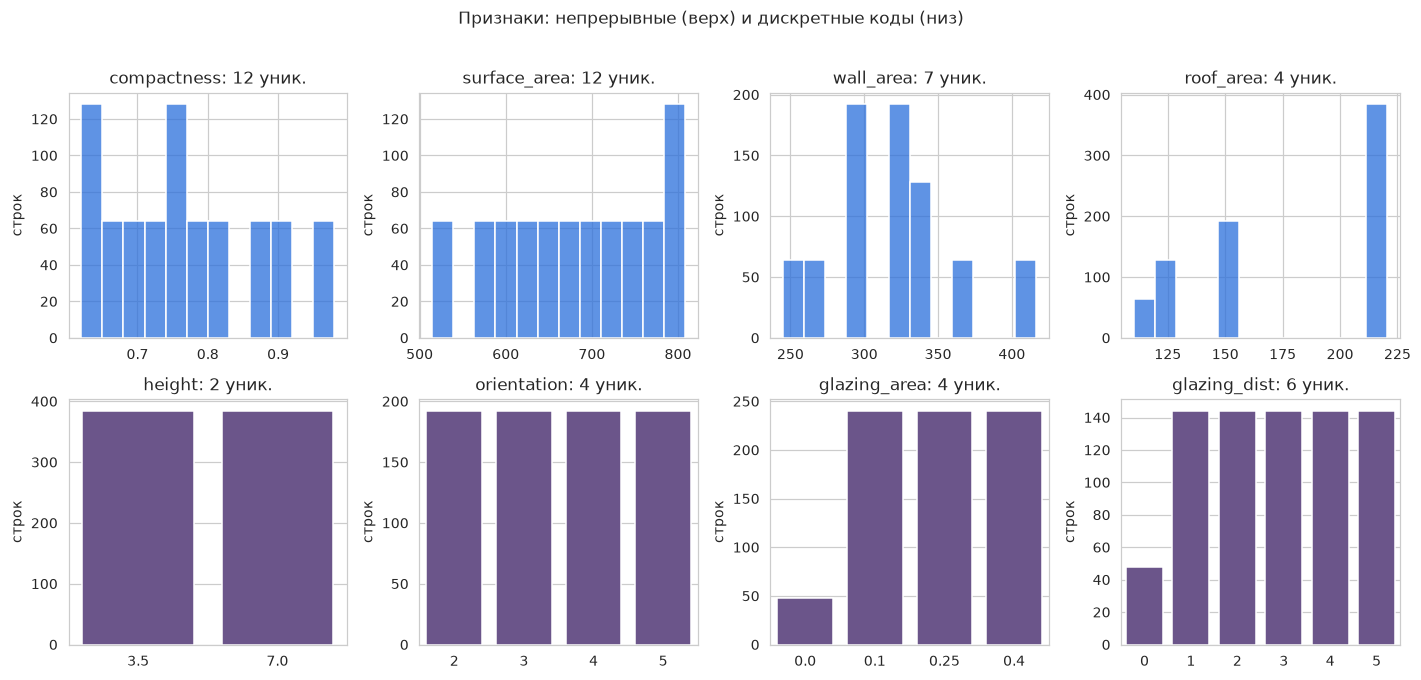

In [8]:
cont = ["compactness", "surface_area", "wall_area", "roof_area"]
disc = ["height", "orientation", "glazing_area", "glazing_dist"]

fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for ax, col in zip(axes[0], cont):
    sns.histplot(df[col], bins=12, ax=ax, color="#2a6fdb")
    ax.set_title(f"{col}: {df[col].nunique()} уник.")
    ax.set_xlabel("")
    ax.set_ylabel("строк")
for ax, col in zip(axes[1], disc):
    sns.countplot(x=col, data=df, ax=ax, color="#6a4c93")
    ax.set_title(f"{col}: {df[col].nunique()} уник.")
    ax.set_xlabel("")
    ax.set_ylabel("строк")

fig.suptitle("Признаки: непрерывные (верх) и дискретные коды (низ)", y=1.02)
fig.tight_layout()
plt.show()

## 5. Целевые величины: доли и проблема двух целей

In [23]:
y1, y2 = df.heating_load, df.cooling_load

pd.DataFrame(
    {
        "Y1 heating_load": [
            y1.mean(),
            y1.median(),
            y1.std(),
            y1.min(),
            y1.max(),
            y1.skew(),
            (y1 >= 30).mean() * 100,
            (y1 < 15).mean() * 100,
        ],
        "Y2 cooling_load": [
            y2.mean(),
            y2.median(),
            y2.std(),
            y2.min(),
            y2.max(),
            y2.skew(),
            (y2 >= 30).mean() * 100,
            (y2 < 15).mean() * 100,
        ],
    },
    index=[
        "среднее",
        "медиана",
        "σ",
        "min",
        "max",
        "skew",
        "доля ≥ 30, %",
        "доля < 15, %",
    ],
).round(2)

,Y1 heating_load,Y2 cooling_load
среднее,22.31,24.59
медиана,18.95,22.08
σ,10.09,9.51
min,6.01,10.90
max,43.10,48.03
skew,0.36,0.40
"доля ≥ 30, %",26.30,33.20
"доля < 15, %",37.11,19.27


In [24]:
r, p = sps.pearsonr(y1, y2)
fit = sps.linregress(y1, y2)
diff = y2 - y1

print(f"r(Y1, Y2) = {r:.4f}, R² = {r**2:.4f}, p {fmt_p(p)}")
print(f"МНК: Y2 = {fit.slope:.4f}·Y1 + {fit.intercept:.4f}")
print(
    f"Y2 − Y1: среднее {diff.mean():.3f}, σ {diff.std():.3f}, диапазон [{diff.min():.2f}; {diff.max():.2f}]"
)
print(f"доля строк Y2 < Y1: {(diff < 0).mean() * 100:.2f}%")
print(f"доля строк с Y1 ≥ 30 и Y2 ≥ 30: {((y1 >= 30) & (y2 >= 30)).mean() * 100:.2f}%")

r(Y1, Y2) = 0.9759, R² = 0.9523, p < 1e-300
МНК: Y2 = 0.9201·Y1 + 4.0636
Y2 − Y1: среднее 2.281, σ 2.229, диапазон [-4.44; 10.69]
доля строк Y2 < Y1: 13.02%
доля строк с Y1 ≥ 30 и Y2 ≥ 30: 25.91%


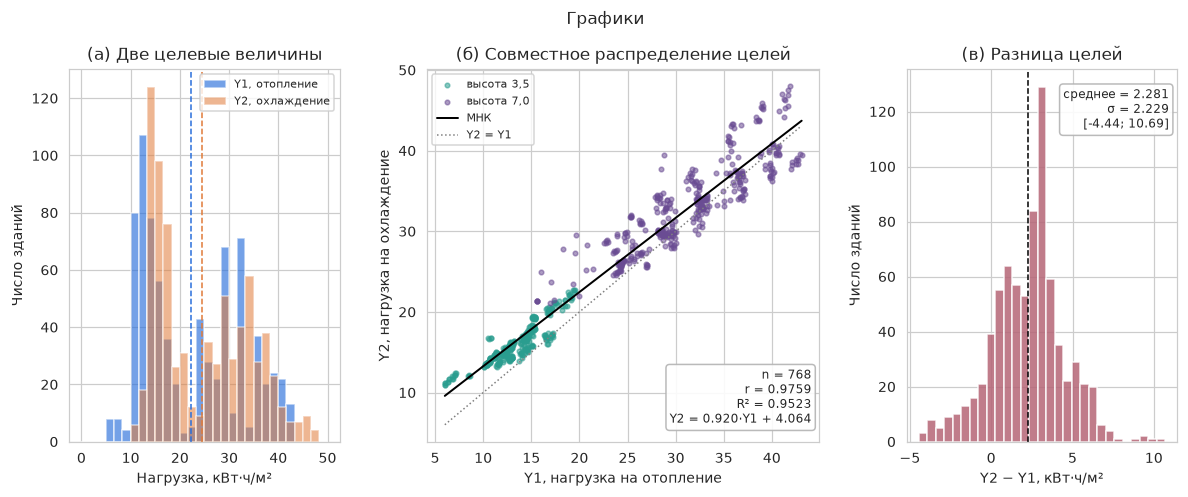

In [27]:
fig = plt.figure(figsize=(13, 4.4))
gs = fig.add_gridspec(1, 3, width_ratios=[1.0, 1.45, 1.0], wspace=0.28)

ax = fig.add_subplot(gs[0, 0])
bins = np.linspace(0, 50, 31)
ax.hist(y1, bins=bins, alpha=0.65, label="Y1, отопление", color="#2a6fdb")
ax.hist(y2, bins=bins, alpha=0.55, label="Y2, охлаждение", color="#e07b39")
ax.axvline(y1.mean(), color="#2a6fdb", ls="--", lw=1)
ax.axvline(y2.mean(), color="#e07b39", ls="--", lw=1)
ax.set_xlabel("Нагрузка, кВт·ч/м²")
ax.set_ylabel("Число зданий")
ax.set_title("(а) Две целевые величины")
ax.legend(fontsize=7)

ax = fig.add_subplot(gs[0, 1])
low = df.height == 3.5
ax.scatter(y1[low], y2[low], s=9, alpha=0.55, color="#2a9d8f", label="высота 3,5")
ax.scatter(y1[~low], y2[~low], s=9, alpha=0.55, color="#6a4c93", label="высота 7,0")
grid = np.linspace(y1.min(), y1.max(), 100)
ax.plot(grid, fit.slope * grid + fit.intercept, color="black", lw=1.3, label="МНК")
ax.plot(grid, grid, color="grey", lw=1, ls=":", label="Y2 = Y1")
ax.set_xlabel("Y1, нагрузка на отопление")
ax.set_ylabel("Y2, нагрузка на охлаждение")
ax.set_title("(б) Совместное распределение целей")
ax.legend(fontsize=7)
ax.text(
    0.98,
    0.04,
    f"n = {len(df)}\nr = {r:.4f}\nR² = {r**2:.4f}\nY2 = {fit.slope:.3f}·Y1 + {fit.intercept:.3f}",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=8,
    bbox={"boxstyle": "round,pad=0.3", "fc": "white", "ec": "0.7", "alpha": 0.9},
)

ax = fig.add_subplot(gs[0, 2])
ax.hist(diff, bins=np.linspace(diff.min(), diff.max(), 30), color="#b56576", alpha=0.85)
ax.axvline(diff.mean(), color="black", ls="--", lw=1)
ax.set_xlabel("Y2 − Y1, кВт·ч/м²")
ax.set_ylabel("Число зданий")
ax.set_title("(в) Разница целей")
ax.text(
    0.97,
    0.95,
    f"среднее = {diff.mean():.3f}\nσ = {diff.std():.3f}\n[{diff.min():.2f}; {diff.max():.2f}]",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=8,
    bbox={"boxstyle": "round,pad=0.3", "fc": "white", "ec": "0.7", "alpha": 0.9},
)

fig.suptitle("Графики", fontsize=11, y=1.0)
plt.show()

Цели сильно связаны (`r = 0,9759`, `R² = 0,9523`), но не совпадают: средняя
разница `Y2 − Y1` равна 2,2806, σ = 2,2287, диапазон — от −4,44 до 10,69, а в
13,02 % строк охлаждение **меньше** отопления. Заменить две цели одной нельзя:
нужны два выхода и раздельные MAE/RMSE по каждой цели.

Распределения целей двугорбые (skew ≈ 0,36/0,40):
это следствие двух уровней высоты, а не выбросов.

## 6. Связи: признаки → цели

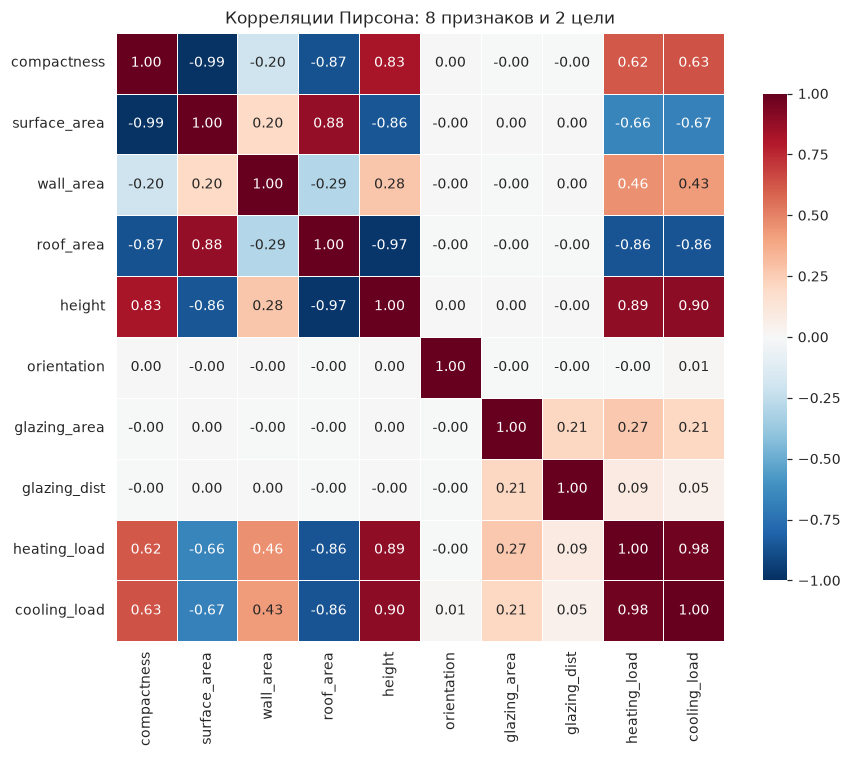

In [28]:
corr = df[FEATURES + TARGETS].corr()

fig, ax = plt.subplots(figsize=(8.2, 6.8))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    ax=ax,
)
ax.set_title("Корреляции Пирсона: 8 признаков и 2 цели")
fig.tight_layout()
plt.show()

In [29]:
rows = []
for col in FEATURES:
    row = {"признак": col}
    for t in TARGETS:
        r, p = sps.pearsonr(df[col], df[t])
        row[f"r {SHORT[t]}"] = round(r, 4)
        row[f"p {SHORT[t]}"] = f"{p:.3g}"
    rows.append(row)

pd.DataFrame(rows).set_index("признак")

,r Y1,p Y1,r Y2,p Y2
признак,,,,
compactness,0.6223,1.59e-83,0.6343,1.06e-87
surface_area,-0.6581,1.69e-96,-0.6730,2.01e-102
wall_area,0.4557,1.22e-40,0.4271,2.11e-35
roof_area,-0.8618,4.92e-228,-0.8625,7.73e-229
height,0.8894,1.14e-262,0.8958,5.86e-272
orientation,-0.0026,0.943,0.0143,0.693
glazing_area,0.2698,2.8e-14,0.2075,6.46e-09
glazing_dist,0.0874,0.0154,0.0505,0.162


In [32]:
def eta_squared(values: pd.Series, groups: pd.Series) -> float:
    grand = values.mean()
    ss_between = sum(
        len(g) * (g.mean() - grand) ** 2 for _, g in values.groupby(groups)
    )
    return ss_between / ((values - grand) ** 2).sum()


groupings = {
    "форма (X1-X4)": df.groupby(SHAPE_COLS).ngroup(),
    "высота (X5)": df.height,
    "ориентация (X6)": df.orientation,
    "площадь остекления (X7)": df.glazing_area,
    "распределение остекления (X8)": df.glazing_dist,
}

rows = []
for name, groups in groupings.items():
    row = {"группа": name, "уровней": groups.nunique()}
    for t in TARGETS:
        row[f"η² {SHORT[t]}"] = eta_squared(df[t], groups)
        row[f"p {SHORT[t]}"] = fmt_p(
            sps.f_oneway(*[g.values for _, g in df[t].groupby(groups)]).pvalue
        )
    rows.append(row)

pd.DataFrame(rows).set_index("группа").round(4)

,уровней,η² Y1,p Y1,η² Y2,p Y2
группа,,,,,
форма (X1-X4),12,0.9083,< 1e-300,0.9217,< 1e-300
высота (X5),2,0.7911,1.14e-262,0.8024,5.86e-272
ориентация (X6),4,0.0000,0.999,0.0006,0.926
площадь остекления (X7),4,0.0815,5.09e-14,0.0449,1.15e-07
распределение остекления (X8),6,0.0424,3.69e-06,0.0180,0.0166


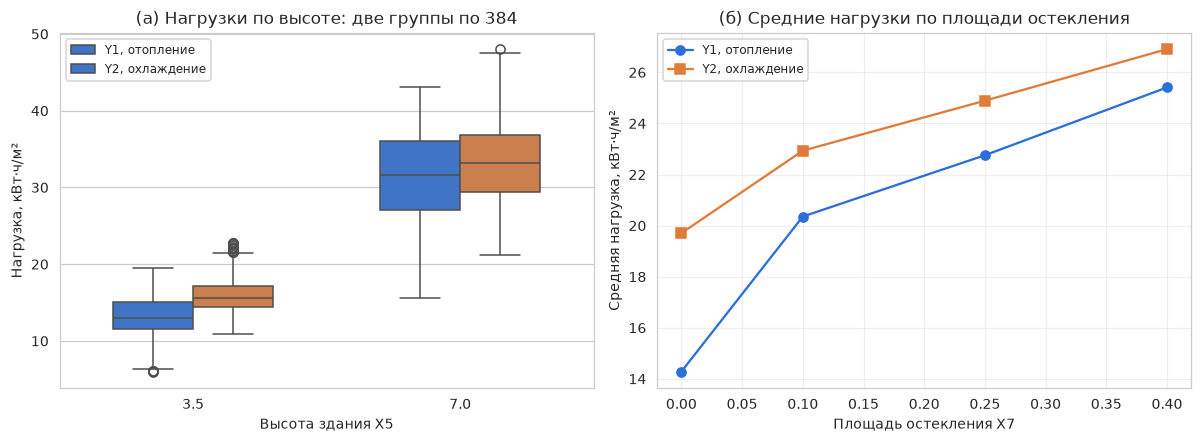

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.1))

long = df.melt(
    id_vars="height", value_vars=TARGETS, var_name="target", value_name="load"
)
sns.boxplot(
    data=long,
    x="height",
    y="load",
    hue="target",
    ax=axes[0],
    palette=["#2a6fdb", "#e07b39"],
    width=0.6,
)
axes[0].set_xlabel("Высота здания X5")
axes[0].set_ylabel("Нагрузка, кВт·ч/м²")
axes[0].set_title("(а) Нагрузки по высоте: две группы по 384")
axes[0].legend(title="", labels=["Y1, отопление", "Y2, охлаждение"], fontsize=8)

means = df.groupby("glazing_area")[TARGETS].mean()
axes[1].plot(
    means.index,
    means["heating_load"],
    marker="o",
    label="Y1, отопление",
    color="#2a6fdb",
)
axes[1].plot(
    means.index,
    means["cooling_load"],
    marker="s",
    label="Y2, охлаждение",
    color="#e07b39",
)
axes[1].set_xlabel("Площадь остекления X7")
axes[1].set_ylabel("Средняя нагрузка, кВт·ч/м²")
axes[1].set_title("(б) Средние нагрузки по площади остекления")
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

Самый сильный драйвер — форма здания: η² = 0,91 (`Y1`) и 0,92 (`Y2`). Высота
объясняет 0,79/0,80, но она не независимый фактор: все 6 форм с высотой 3,5
имеют `compactness` 0,62–0,74, а все 6 форм с высотой 7,0 — 0,76–0,98; форм с
обеими высотами 0. Эффект высоты неотделим от формы.

Ориентация не даёт сигнала: η² = 0,0000/0,0006, ANOVA p = 0,999/0,926 — по
коду ориентации это не «слабая линейная связь», а полное отсутствие эффекта.
Остекление даёт монотонный, но скромный вклад: η² = 0,08/0,045 (p ≈ 5·10⁻¹⁴ и
1·10⁻⁷). Распределение остекления — 0,042/0,018 (p = 3,7·10⁻⁶ и 0,017).

Сильнейшие линейные связи: `height` ~ `Y1` r = 0,889, `roof_area` ~ `Y1`
r = −0,862, `compactness` ~ `Y1` r = 0,622. Внутри признаков почти дублирование:
`compactness` ~ `surface_area` r = −0,9919, `roof_area` ~ `height` r = −0,9725.

## 7. Выводы

1. Пропусков, дубликатов строк и выбросов по IQR в данных нет: **0**.
2. Датасет сбалансирован: **12** форм здания × **64** строки = 768.
3. Уровней высоты — **2**, по **384** строки на каждый; форм с обеими высотами — **0**.
4. `surface_area = wall_area + 2·roof_area` выполняется точно, максимальная ошибка — **0**.
5. Ранг матрицы стандартизованных признаков — **7** из 8; число обусловленности — **3,31·10¹⁵**.
6. Средняя нагрузка на охлаждение больше отопления на **2,2806** кВт·ч/м² (σ разницы **2,2287**), знак разницы не постоянен: Y2 < Y1 в **13,02 %** строк.
7. Цели сильно коррелированы: **r = 0,9759**, R² = 0,9523.
8. Доля зданий с высокой нагрузкой: **26,30 %** по Y1 (≥ 30) и **33,20 %** по Y2; обе цели ≥ 30 у **25,91 %** строк.
9. Форма здания объясняет **η² = 0,91** дисперсии Y1 и **0,92** Y2; высота — **0,79** и **0,80**.
10. Ориентация не влияет на нагрузку: η² = **0,0000/0,0006**, ANOVA p = **0,999/0,926**.
11. Самая сильная коллинеарность — `compactness` ~ `surface_area`: **r = −0,9919**.